# orbit-agent: the experiments, in the order we did them

**The project in one line:** a satellite takes far more photos than it can send down, so an AI on board
decides what goes down, and the ground must be able to **trust the numbers** it makes from what arrives.

**Read [01_data.ipynb](01_data.ipynb) first.** It shows what is in the photos and what is messy, and most
of the later decisions rest on it. This notebook then goes through every experiment from 18 to 22 October
2026, in order. Each one has the same parts:

- **Question:** what we wanted to know
- **What we did:** in plain words
- **Result:** loaded from that experiment's folder in `results/` (nothing is typed in by hand)
- **What we learned**, and what it made us do next

Experiments 1-7 measured *how many labels look right*. Experiment 8 showed that this score can't fail, which
changed the question to *can the ground trust the numbers?* (experiments 9-11). Experiment 12 retrains the
onboard model using what the data analysis found.

This notebook only reads saved results, so it runs in about a minute with no downloads or model calls.

In [1]:
# Setup: run from the project folder, load the helpers
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, ".")

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.paths import find, result

pd.options.display.float_format = lambda v: f"{v:g}"  # plain numbers, no 1.0e+00
pd.set_option("display.max_colwidth", 60)


def figure(name, width=900):
    """Show a chart from docs/figures/."""
    display(Image(filename=f"docs/figures/{name}", width=width))


def read(name):
    """A result file, from wherever it lives in results/."""
    return pd.read_csv(result(name))

## Experiment 1 · Sun 18 Oct · A satellite on your desk

**Question.** How often can a real satellite talk to a ground station in India, and how much can it send?

**What we did.** Took the real orbit data (TLE) of Sentinel-2A and computed every pass over Delhi, Bengaluru
and Svalbard (a polar station) for one day. A *pass* is the few minutes when the station can hear the
satellite. Then a *photo replay*: the satellite "takes" a photo every 30 s in daylight and queues it for
the next pass (`src/orbit/`).

In [2]:
from datetime import datetime, timedelta, timezone
from src.orbit.contact_windows import contact_windows, load_satellite

sat = load_satellite(tle_path="data/raw/tle/40697.tle")   # saved orbit data, so the numbers repeat
start = datetime(2026, 10, 19, tzinfo=timezone.utc)
rows = []
for station in ["delhi", "bengaluru", "svalbard"]:
    passes = contact_windows(sat, station, start, start + timedelta(days=1))
    minutes = sum(p.minutes for p in passes)
    rows.append({"station": station, "passes per day": len(passes), "minutes in contact": round(minutes, 1),
                 "share of the day": f"{minutes / 1440:.1%}", "MB per day at 1 Mbps": round(sum(p.data_mb(1) for p in passes))})
pd.DataFrame(rows)

,station,passes per day,minutes in contact,share of the day,MB per day at 1 Mbps
0,delhi,3,24.6,1.7%,185
1,bengaluru,3,25.5,1.8%,191
2,svalbard,12,109.2,7.6%,819


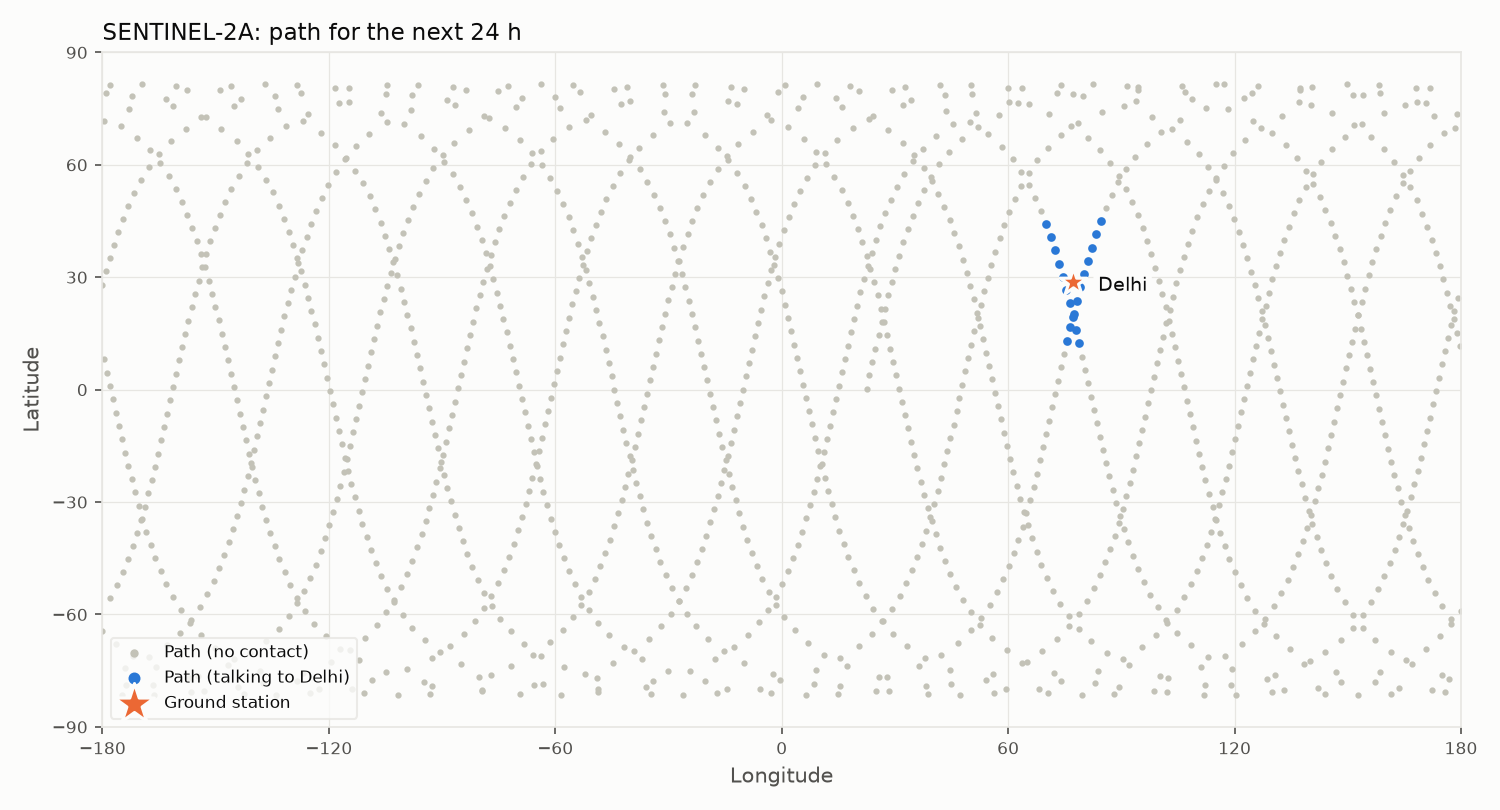

In [3]:
figure("../../results/01_orbit/orbit_map.png", 800)

**What we learned.** Sentinel-2A can talk to Delhi only about **1.4-1.7% of the day** (2-3 passes of up to
about 10 minutes; on 19 Oct three passes, 25 minutes in all). A polar station (Svalbard) hears it about 8% of the day. So most photos taken over India never come
down: choosing what to send matters most for stations like Delhi and Bengaluru.

*Results: `results/01_orbit/`. Rerun: `python -m src.orbit.contact_windows`.*

## Experiment 2 · Sun 18 Oct · Gemma 3 with no training

**Question.** NASA JPL's NAVI-Orbital flew Gemma 3 (a 4-billion-weight vision-language model) in April 2026.
Can it label satellite photos with no training at all?

**What we did.** Ran Gemma 3 4B on a laptop (Ollama) on two labelled data sets (see 01_data):
EuroSAT (real Sentinel-2, 64 x 64 px, 10 classes), trying 3 prompts and 3 image sizes, and AID
(sharp aerial photos, 600 x 600 px, 30 classes, the data set NAVI used).

In [4]:
rows = []
for path in find("baseline_*.csv"):
    parts = path.stem.split("_")        # baseline_<dataset>_gemma3-4b_<prompt>_<size>px_<date>_<time>
    answers = pd.read_csv(path)
    tagged = len(parts) > 4
    rows.append({"data set": parts[1], "prompt": parts[3] if tagged else "first try",
                 "image size": parts[4] if tagged else "448px", "photos": len(answers),
                 "right": f"{answers['correct'].mean():.0%}", "file": path.name})
pd.DataFrame(rows)

,data set,prompt,image size,photos,right,file
0,aid,v1,448px,30,73%,baseline_aid_gemma3-4b_v1_448px_20261018_1855.csv
1,aid,v1,448px,300,61%,baseline_aid_gemma3-4b_v1_448px_20261018_2302.csv
2,eurosat,first try,448px,30,20%,baseline_eurosat_20261018_1449.csv
3,eurosat,first try,448px,100,26%,baseline_eurosat_20261018_1505.csv
4,eurosat,v0,448px,10,20%,baseline_eurosat_gemma3-4b_v0_448px_20261018_1514.csv
5,eurosat,v1,224px,100,32%,baseline_eurosat_gemma3-4b_v1_224px_20261018_1602.csv
6,eurosat,v1,448px,10,20%,baseline_eurosat_gemma3-4b_v1_448px_20261018_1515.csv
7,eurosat,v1,448px,100,29%,baseline_eurosat_gemma3-4b_v1_448px_20261018_1528.csv
8,eurosat,v1,896px,100,30%,baseline_eurosat_gemma3-4b_v1_896px_20261018_1614.csv
9,eurosat,v2,448px,10,10%,baseline_eurosat_gemma3-4b_v2_448px_20261018_1516.csv


**What we learned.**
- **EuroSAT: 22-32% on the 100-photo runs, whatever we tried** (the 10- and 30-photo rows are quick tests).
  Prompts and image size made no real difference. The 64 x 64 px
  photos are too small, and the model answers "Forest" for almost everything.
- **AID: 61-65% right** (sharp photos help a lot). NAVI reported 88.16%, but on AID cut to 18 easier classes;
  scored their way, ours gets 76.5% (fair comparison in `archive/experiment_log.md`).
- About 7.5 s per photo on the laptop.

*Results: `results/02_gemma/`. Rerun: `python -m src.eval.baseline_eurosat --dataset aid` (needs Ollama, ~40 min).*

## Experiment 3 · Mon 19 Oct · Teaching the agent to say "not sure" (agents v1-v3)

**Question.** Gemma is wrong about a third of the time. Can the agent tell *when* it is wrong, label only the
photos it is sure about, and send the rest as full photos?

**What we did.** Tested four "not sure" signals on 300 AID photos never used before (photos 21-30 of each
class). Then built agents v1-v3 and ran them on the photo replay of experiment 1. The score at the time:
*how many photos reached the ground correctly* (a right label or a full photo), plus *wrong labels sent*.

In [5]:
from src.eval.confidence_test import evaluate
evaluate(result("confidence_aid_test_gemma3-4b_r3_n10_skip20.csv"), repeats=3)


Test set: 300 new AID photos. First answer right: 189 (63%), wrong: 111.
Majority vote of 3 asks: 191 right (64%).
Signal B learned from: baseline_aid_gemma3-4b_v1_448px_20261018_2302.csv

Signal                    Ranking (AUROC)   Wrong answers caught when flagging
                         0.5=useless 1=best      10%    20%    30%
A. Several answers                   0.50       8%    18%    26%
B. Confused classes                  0.77      20%    34%    50%
C. Answer margin                     0.63      15%    31%    42%
D. Agreement (3 asks)                0.68      20%    34%    48%
A + D + C combined                   0.71      19%    39%    50%

Agent v2 rule (A or D or margin < 8, fixed before testing): flags 134 photos (45%), catches 72 of 111 wrong answers (65%).
Of the photos it calls sure, 127 of 166 are right (77%).



Answers: /Users/subhammahapatra/Downloads/SubhamPortfolio/orbit-agent/results/03_agents_v1_v3/confidence_aid_test_gemma3-4b_r3_n10_skip20.csv
Chart:   /Users/subhammahapatra/Downloads/SubhamPortfolio/orbit-agent/results/03_agents_v1_v3/confidence_aid_test_gemma3-4b_r3_n10_skip20.png


In [6]:
agents = read("agents_delhi_final_equal_20261019_1229.csv")
agents["cell"] = (100 * agents["correct"] / agents["photos"]).round().astype(int).astype(str) + "% / " + agents["wrong_labels"].astype(str)
agents["rate"] = agents["rate_mbps"].map(lambda r: f"{r:g} Mbps")
agents.pivot(index="policy", columns="rate", values="cell")[["0.25 Mbps", "0.5 Mbps", "1 Mbps", "2 Mbps", "4 Mbps"]].rename_axis(columns="downlink (Mbps) ->  correct / wrong labels")

downlink (Mbps) -> correct / wrong labels,0.25 Mbps,0.5 Mbps,1 Mbps,2 Mbps,4 Mbps
policy,,,,,
agent v1,70% / 331,74% / 282,84% / 173,95% / 51,100% / 0
agent v2,58% / 132,72% / 129,89% / 85,97% / 29,100% / 0
agent v3,68% / 192,79% / 164,92% / 90,99% / 6,100% / 0
agent v3-lite,65% / 204,78% / 167,91% / 99,99% / 7,100% / 0
caption all,63% / 404,63% / 404,63% / 404,63% / 404,63% / 404
send all raw,15% / 0,30% / 0,60% / 0,89% / 0,100% / 0


**What we learned.**
- **The best "not sure" signal is free:** "is this a class the model often confuses?" (AUROC 0.77) beats
  asking three times (0.68) and the model's own token probability (0.63, it is ~100% sure even when wrong).
- On this score agent v3 got **92% vs 60%** for raw photos at 1 Mbps, with half the wrong labels of v1.
- *Later (experiment 8) we found this score can't fail, so these numbers are history, not the result.*

*Results: `results/03_agents_v1_v3/`. Rerun: `python -m src.eval.run_agent`.*

## Experiment 4 · Tue 20 Oct · A small trained head beats the big model

**Question.** Gemma is slow (7.5 s) and often wrong. Would a frozen image model plus a tiny trained classifier
do better?

**What we did.** SigLIP (the image encoder family Gemma 3 uses) turns each photo into 768 numbers; it is never
changed ("frozen"). A logistic regression on top (about 30 KB) learns the 30 classes from 20 labelled photos
per class. A bigger version (SigLIP 400M, all 9,100 training photos) ran on a free Kaggle GPU.

In [7]:
from src.model.head import calibration_error

def summary(name, label, photos_used):
    a = read(name)
    right = a["guess"] == a["truth"]
    sure_and_wrong = int(((a["p"] > 0.96) & ~right).sum()) if "p" in a else None
    return {"labeller": label, "labelled photos used": photos_used, "right": f"{right.mean():.1%}",
            "calibration error": round(calibration_error(a["p"].values, right.values), 3) if "p" in a else None,
            "wrong but over 96% sure": sure_and_wrong}

pd.DataFrame([
    summary("head_aid_siglip-base_n20_final.csv", "small head: SigLIP-base (90M) + 30 KB", 600),
    summary("head_aid_siglip_final.csv", "big head: SigLIP 400M + head (Kaggle)", 9100),
    summary("confidence_aid_test_gemma3-4b_r3_n10_skip20.csv", "Gemma 3 4B, no training", 0),
])

,labeller,labelled photos used,right,calibration error,wrong but over 96% sure
0,small head: SigLIP-base (90M) + 30 KB,600,95.7%,0.036,0
1,big head: SigLIP 400M + head (Kaggle),9100,98.3%,0.021,5
2,"Gemma 3 4B, no training",0,63.0%,NaN,NaN


**What we learned.**
- **95.7% vs Gemma's 63%**, 26 ms per photo instead of 7.5 s, and the chances are honest (calibration error 0.04).
- **More accurate is not more trustworthy:** the big head is right 98.3% of the time, but all 5 of its
  mistakes were over 96% sure. A rule that only double-checks unsure photos can never catch those.
- Caveat: the head learned from labelled photos, Gemma saw none (a fair zero-shot rival comes in experiment 10).

*Results: `results/04_decision_head/`. Rerun: `python -m src.model.head --backbone siglip-base --train-per-class 20`.*

## Experiment 5 · Tue 20 Oct · Real Sentinel-2 photos

**Question.** AID photos are aerial. Does the head work on real satellite photos (EuroSAT, Sentinel-2)?

**What we did.** (1) Used the AID head as it is, matching its classes to EuroSAT's. (2) Trained a new head
on 100 EuroSAT photos per class. Tested on 1,000 EuroSAT photos never used for building.

In [8]:
def right(name):
    a = read(name)
    return f"{(a['guess'] == a['truth']).mean():.1%}"

pd.DataFrame([
    {"labeller": "AID head, used as it is", "right": right("sentinel_test1_aid_head_siglip-base.csv")},
    {"labeller": "new small head, 100 Sentinel-2 photos per class", "right": right("head_eurosat_siglip-base_n100_final.csv")},
    {"labeller": "new big head (SigLIP 400M, Kaggle)", "right": right("head_eurosat_siglip_n100_final.csv")},
    {"labeller": "Gemma 3 4B, no training (its 100 photos)", "right": right("baseline_eurosat_gemma3-4b_v1_448px_20261018_1528.csv")},
])

,labeller,right
0,"AID head, used as it is",33.2%
1,"new small head, 100 Sentinel-2 photos per class",92.8%
2,"new big head (SigLIP 400M, Kaggle)",94.8%
3,"Gemma 3 4B, no training (its 100 photos)",29.0%


**What we learned.** A head trained on one camera doesn't transfer to another (33%). **Retrain the 30 KB head
per camera** (about 1,000 labelled photos), not the big model: 92.8%. The 400M model adds 2 points for
15-20x the compute. Data analysis (01_data) later showed this number is not inflated by neighbouring tiles.

*Results: `results/05_sentinel2/`. Rerun: `python -m src.eval.sentinel_test`.*

## Experiment 6 · Tue 20 Oct · A tiny CNN, and how many labels each model needs

**Question.** Is a frozen 90M model even needed? A tiny CNN (MobileNetV3-Small, 1.5M weights, all trained)
is far cheaper. And how many labelled photos does each need?

**What we did.** Trained both with 5, 10, 20, 50 and 100 labelled photos per class (3 random picks each),
on AID and EuroSAT, on a Kaggle GPU.

In [9]:
curve = read("label_curve_20261020_0752.csv")
table = curve.groupby(["dataset", "model", "per_class"])["accuracy"].mean().mul(100).unstack("per_class")
table.columns = [f"{c} per class" for c in table.columns]
table

5 per class  10 per class  20 per class  \
dataset model                                                                   
aid     head (frozen SigLIP-base)           89.67       91.5567         94.22   
        tiny CNN (MobileNetV3-Small)        67.89       80.4433         85.89   
eurosat head (frozen SigLIP-base)            79.3       84.4333          88.5   
        tiny CNN (MobileNetV3-Small)      44.1667          61.7          81.4   

                                      50 per class  100 per class  
dataset model                                                      
aid     head (frozen SigLIP-base)            94.78          94.67  
        tiny CNN (MobileNetV3-Small)       88.5533        93.7767  
eurosat head (frozen SigLIP-base)          91.4333           92.8  
        tiny CNN (MobileNetV3-Small)       91.3667        95.4333

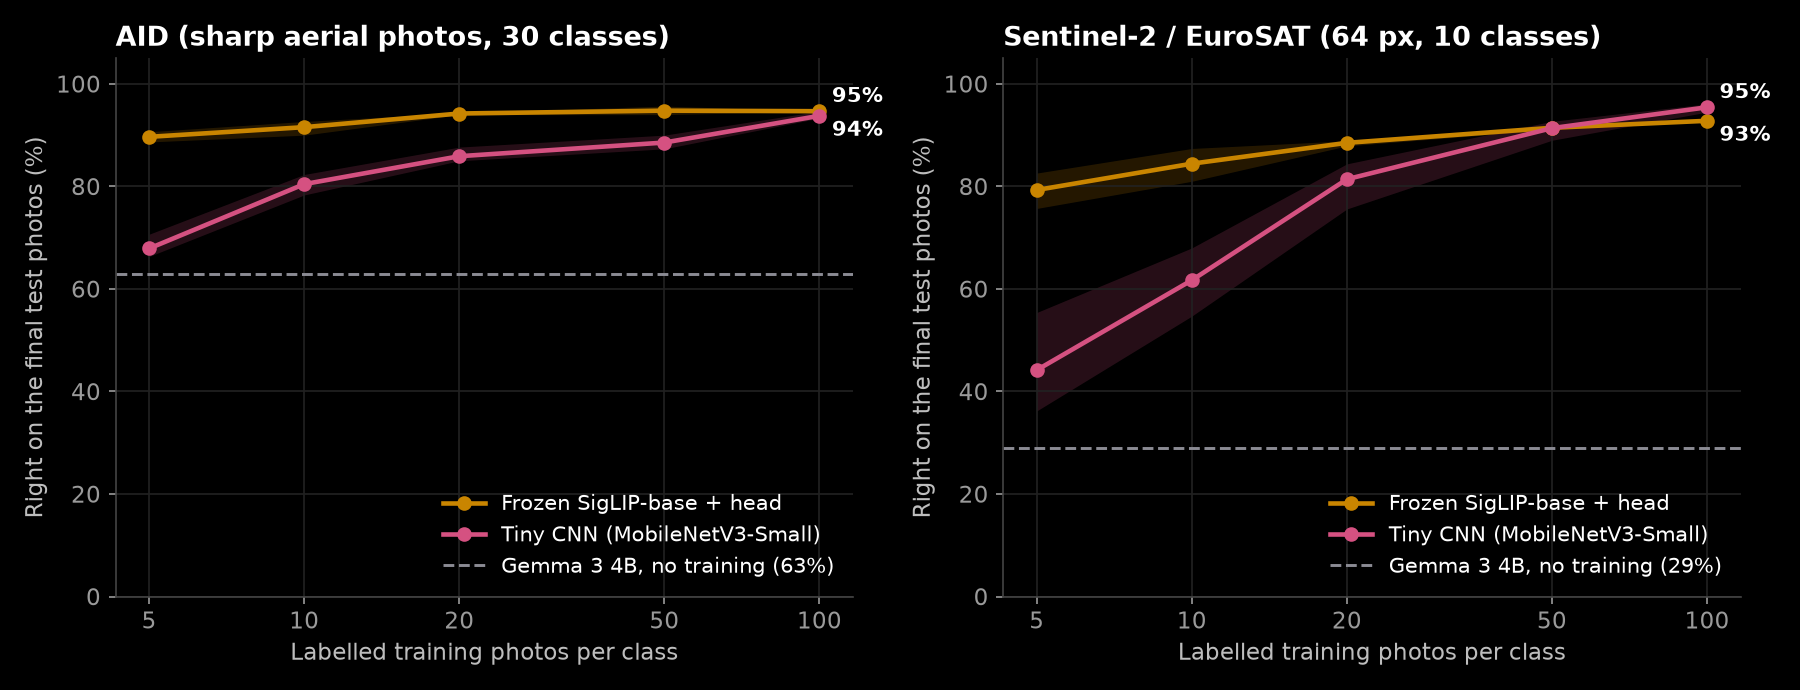

In [10]:
figure("label_curve.png")

**What we learned.** With few labels the frozen head wins clearly (5 per class: 79-90% vs 44-68%). On
Sentinel-2 the CNN catches up at about 50 per class and is ahead at 100 (95% vs 93%), at 1/300 of the
compute. So: frozen head at the start of a mission, tiny CNN once many labels exist.

*Results: `results/06_cnn_label_curve/`. Rerun: `python -m src.eval.label_curve` (Kaggle GPU).*

## Experiment 7 · Tue 20 Oct · Do the results hold?

**Question.** Were we lucky with one day, one station, one photo order?

**What we did.** Re-ran the replay over 7 days x 3 stations x 3 photo orders (21 runs per station), and
tested the head on 1,900 photos never touched by any model or setting (overfitting check).

In [11]:
bars = read("replay_bars_20261020_1413.csv")
delhi = bars[(bars.dataset == "aid") & (bars.station == "delhi") & (bars.rate_mbps == 1)]
delhi.groupby("policy").agg(correct_mean=("correct_pct", "mean"), correct_sd=("correct_pct", "std"),
                            wrong_labels_mean=("wrong_labels", "mean")).round(1)

,correct_mean,correct_sd,wrong_labels_mean
policy,,,
agent v1,84.3,2,158.8
agent v2,86.6,4.3,87.1
agent v3,91.1,3,83.5
agent v3-lite,90.8,2.7,87.2
agent v4 (CNN),98.6,0.7,14.4
agent v4 (head),100,0,0
caption all,63.4,0.7,372
send all raw,58,5.3,0


**What we learned.**
- The order of the policies never changes; the overfitting check found none (fresh photos: AID 94.4% vs
  94.3% on the final test, Sentinel-2 92.5% vs 92.7%; `python -m src.eval.overfit_check`).
- But the frozen head scored **100.0 ± 0.0%** on every one of 21 runs. A score that is always 100% is a
  ceiling, not a strength. That was the warning sign for experiment 8.

*Results: `results/07_robustness/`. Rerun: `python -m src.eval.replay_bars`.*

## Experiment 8 · Tue 20 Oct · The turning point: plain compression

**Question.** A senior-researcher style review asked: is onboard AI needed at all? What if the satellite just
re-saves every photo as a smaller JPEG until the pass fits ("compress to fit"), with no AI?

**What we did.** Ran compress-to-fit with a real JPEG ladder at many data ratios R (photos taken / what the
passes can send), with the same bytes and the same number of human checks as every other method.

In [12]:
sweep = read("compress_sweep_20261020_1938.csv")
sweep["R"] = sweep.groupby("rate_mbps")["R"].transform("mean").round(0)
t = sweep[sweep.method.isin(["compress to fit", "raw random"])].groupby(["rate_mbps", "R", "method"])["lenient_pct"].mean().unstack("method")
t.columns = [f"{c}: photos seen (%)" for c in t.columns]
t.sort_index(ascending=False).round(0)

,,compress to fit: photos seen (%),raw random: photos seen (%)
rate_mbps,R,,
1,1,100,58
0.5,3,100,34
0.25,6,100,18
0.1,14,100,7
0.05,28,90,4
0.025,56,63,2
0.01,140,31,1
0.005,281,16,0
0.0025,562,8,0


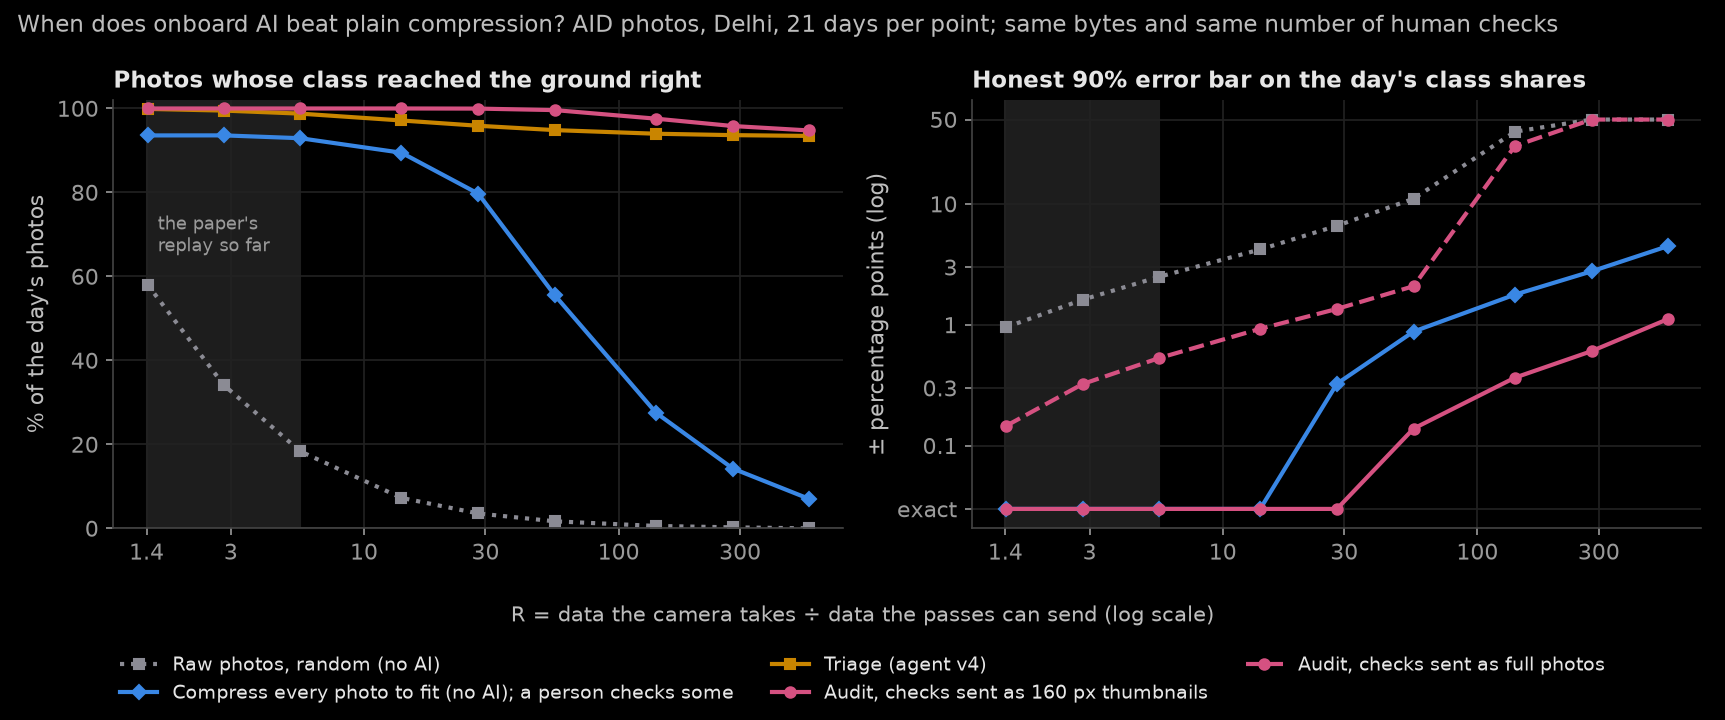

In [13]:
figure("audit_rsweep.png")

**What we learned.** In the range we had used (R up to about 7), compression sends **every** photo, so it also
scores 100% on the old score with no AI at all. The old score counted a 50-byte label the same as a 280 KB
photo, so it could never fail. Onboard AI only matters above about R = 30.

**This changed the question** from "how many labels look right?" to **"can the ground trust the numbers it
makes from the data, and how sure can it be?"** The product became: *the share of the day's photos in each
class (cloud, cropland, water...), with an honest 90% error bar.*

*Results: `results/08_compression/`. Rerun: `python -m src.eval.compress_test`.*

## Experiment 9 · Tue 20 Oct · The audited downlink, and a satellite that checks itself

**Question.** If the onboard model is broken (a new camera, a radiation bit flip, a damaged lens), do the
ground's numbers go wrong without anyone noticing? Can random checks fix that?

**What we did.**
- **Real data:** a replay of what Sentinel-2A *really* photographed at each moment of its orbit, 6-19 Oct 2026
  (3,527 photos, labelled from the image's cloud map and ESA WorldCover; see 01_data). Head trained on 6-12 Oct,
  tested on 13-19 Oct.
- **Audit:** label every photo, then send full photos picked **at random with known chances** (unsure photos
  more likely, every photo keeps a minimum chance). The ground corrects the labels with those checks.
- **Self-check:** if the checked mistakes are 1.5x bigger than the model expected, switch to a safe mode.
- Compared with *labels only* (like NAVI), *triage* (send the least-sure photos, like agent v4) and random raw photos,
  for a healthy model and five broken ones, 3 stations x 7 days x 3 photo orders.

In [14]:
audit = read("audit_summary_real_20261022_1318.csv")
methods = ["labels only", "triage (v4)", "raw random", "audit, floor 0.5", "audit, self-check"]
at = audit[(audit.rate_mbps == 0.05) & audit.method.isin(methods)]
cell = at.groupby(["scenario", "method"]).agg(error=("rmse_pts", "mean"), held=("holds_scaled+1", "mean"))
cell = cell["error"].round(1).astype(str) + " pts / " + (100 * cell["held"]).round().astype(int).astype(str) + "%"
cell.unstack("method")[methods].rename_axis(columns="0.05 Mbps: error / 90% bar held")

0.05 Mbps: error / 90% bar held,labels only,triage (v4),raw random,"audit, floor 0.5","audit, self-check"
scenario,,,,,
bit flips,10.6 pts / 27%,10.8 pts / 27%,5.9 pts / 96%,8.1 pts / 91%,5.5 pts / 97%
damaged camera: blur,4.5 pts / 51%,3.3 pts / 67%,5.9 pts / 96%,3.7 pts / 97%,3.6 pts / 97%
damaged camera: noise,4.0 pts / 51%,2.7 pts / 71%,5.9 pts / 96%,4.2 pts / 97%,4.0 pts / 97%
healthy head,1.9 pts / 80%,1.5 pts / 84%,5.9 pts / 96%,3.5 pts / 99%,3.6 pts / 98%
new place (EuroSAT head),19.5 pts / 9%,16.6 pts / 20%,5.9 pts / 96%,8.3 pts / 97%,5.3 pts / 98%
silent swap,1.7 pts / 82%,1.5 pts / 84%,5.9 pts / 96%,3.8 pts / 99%,3.6 pts / 98%


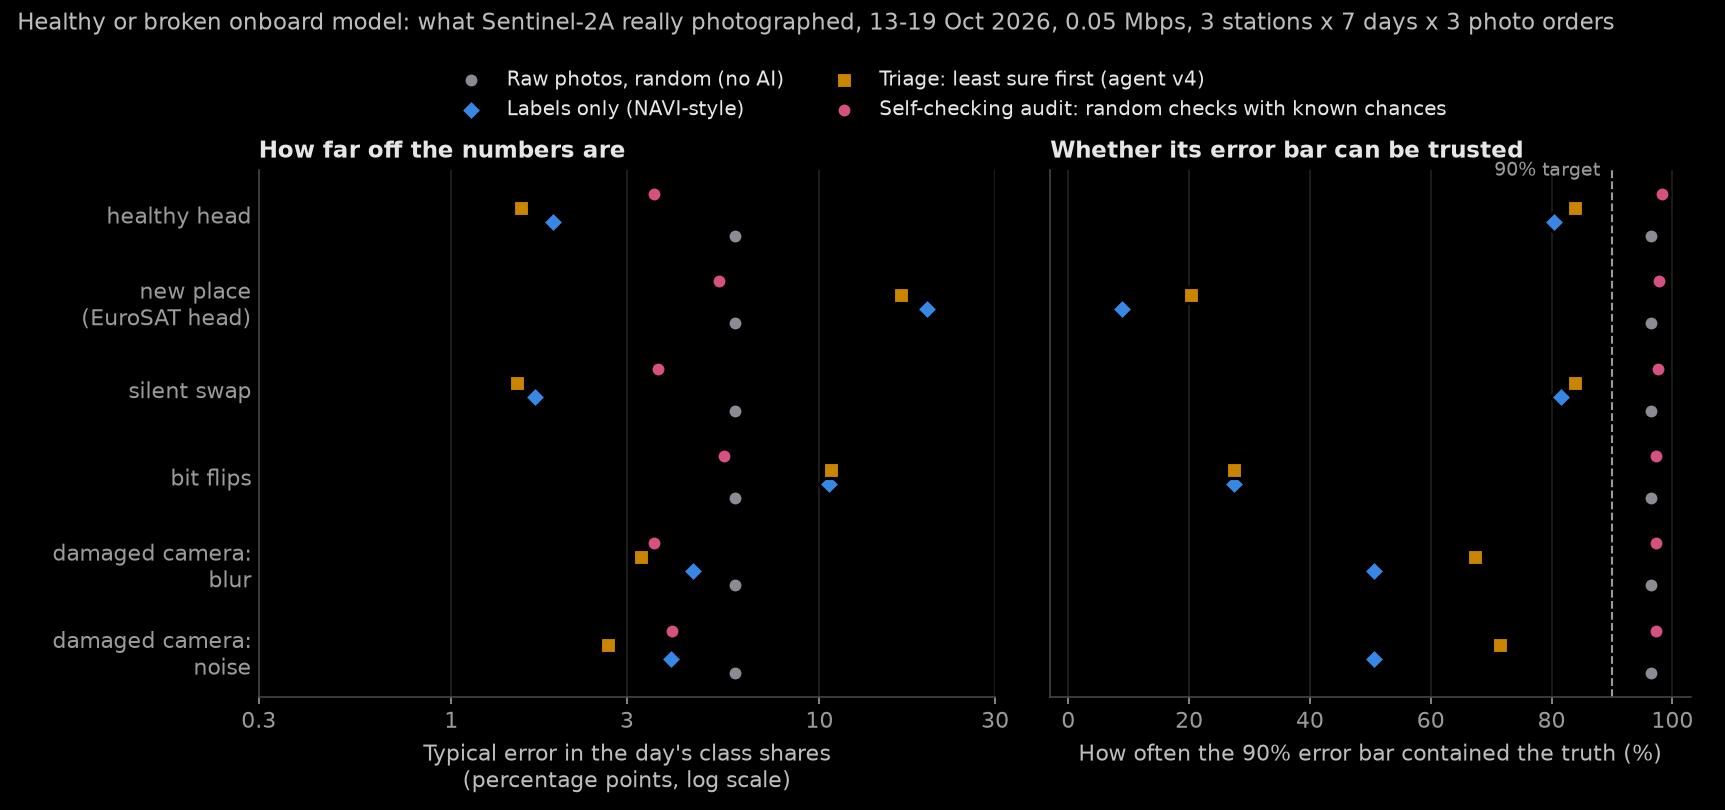

In [15]:
figure("audit_honesty_real.png")

In [16]:
loop = read("audit_loop_real_0.1mbps_20261020_2000.csv")
loop[loop.method == "closed loop"].groupby("day")[["head_right", "labels_so_far"]].mean().round(2)

,head_right,labels_so_far
day,,
2026-10-13,0.46,74
2026-10-14,0.68,114
2026-10-15,0.77,164
2026-10-16,0.83,215
2026-10-17,0.77,255
2026-10-18,0.78,296
2026-10-19,0.8,356


**What we learned.**
- **Today's designs fail silently.** With a broken model, labels-only and triage are 10-20 points off and their
  error bars hold only 9-27% of the time. Even a healthy model's labels mislead on real photos (bar held 80%).
- **The audit stays honest** whatever the model is like. With the self-check it also beats random raw photos
  when the model is broken (5.3-5.5 vs 5.9 points) and its bars hold 97-98%.
- A minimum check chance of 0.5 is nearly free insurance (`results/09_audit/audit_floor_*.csv`).
- **A new camera can learn from its own checks:** from 46% to 83% right in 4 days.

*Results: `results/09_audit/`. Rerun: `python -m src.eval.audit_test --data real`.*

## Experiment 10 · Thu 22 Oct · Fair rivals and guaranteed error bars

**Question.** Three open doubts: (1) Gemma had only been compared with trained models; (2) the default error bar
uses a bell-curve approximation, so is it really safe? (3) Can this run on flight-like hardware?

**What we did.** (1) SigLIP with class names only ("a satellite photo of forest."), no training. (2) A *betting*
error bar (Waudby-Smith & Ramdas) that needs no approximation. (3) Timed every onboard step.

In [17]:
pd.DataFrame([{"data set": d, "SigLIP zero-shot (no training)": right(f"zeroshot_{d}_siglip-base_final.csv"),
               "Gemma 3 4B (no training)": g} for d, g in [("aid", "63%"), ("eurosat", "29%")]])

,data set,SigLIP zero-shot (no training),Gemma 3 4B (no training)
0,aid,66.3%,63%
1,eurosat,40.8%,29%


In [18]:
sc = audit[(audit.method == "audit, self-check") & audit.rate_mbps.isin([0.05, 0.25])]
sc.groupby("rate_mbps").agg(**{"default bar held": ("holds_scaled+1", "mean"), "default worst class": ("holds_scaled+1_worst_class", "min"),
                               "default ± pts": ("halfwidth_scaled+1_pts", "mean"), "betting bar held": ("holds_betting", "mean"),
                               "betting worst class": ("holds_betting_worst_class", "min"), "betting ± pts": ("halfwidth_betting_pts", "mean")}).round(2)

,default bar held,default worst class,default ± pts,betting bar held,betting worst class,betting ± pts
rate_mbps,,,,,,
0.05,0.98,0.81,11.67,1,1,26.45
0.25,0.96,0.81,6.96,1,0.95,7.65


In [19]:
read("bench_Darwin-arm64_20261022_1320.csv")[["step", "ms_per_photo"]]

,step,ms_per_photo
0,"image model, batch 1",26.86
1,"image model, batch 8",19.07
2,small head (CPU),0.0044
3,"audit sampler, one pass of 500 photos",0.001


**What we learned.** A 90M image model with no training already beats the 4B VLM (66% vs 63% on AID, 41% vs 29%
on Sentinel-2). The betting bar held for every class in every setting, at 1.1-2.4x the width: report both.
All onboard steps take about 19 ms per photo on a laptop (a photo every 30 s); the Jetson script is ready.

*Results: `results/10_rivals/`. Rerun: `python -m src.model.zeroshot`, `python -m src.eval.jetson_bench`.*

## Experiment 11 · Thu 22 Oct · Beyond accuracy

**Question.** Everything so far was judged mostly on accuracy. What does a confusion matrix and per-class
scoring show?

**What we did.** Balanced accuracy, per-class precision / recall / F1, macro-F1, Cohen's kappa and calibration
for every labeller on every test set.

In [20]:
m = read("metrics_summary_20261022_1358.csv")
m[["test_set", "model", "photos", "accuracy", "balanced_accuracy", "macro_f1", "kappa", "ece"]].round(3)

,test_set,model,photos,accuracy,balanced_accuracy,macro_f1,kappa,ece
0,aid,small head (SigLIP-base + 30 KB head),300,0.957,0.957,0.956,0.955,0.036
1,aid,big head (SigLIP 400M + head),300,0.983,0.983,0.983,0.983,0.021
2,aid,tiny CNN (MobileNetV3-Small),300,0.85,0.85,0.849,0.845,0.049
3,aid,SigLIP zero-shot,300,0.663,0.663,0.638,0.652,0.046
4,aid,Gemma 3 4B (no training),300,0.63,0.63,0.608,0.617,NaN
5,eurosat,small head (SigLIP-base + 30 KB head),1000,0.928,0.928,0.928,0.92,0.016
6,eurosat,big head (SigLIP 400M + head),1000,0.948,0.948,0.948,0.942,0.014
7,eurosat,tiny CNN (MobileNetV3-Small),1000,0.946,0.946,0.945,0.94,0.016
8,eurosat,SigLIP zero-shot,1000,0.408,0.408,0.322,0.342,0.102
9,eurosat,"Gemma 3 4B (no training, its 100 photos)",100,0.29,0.29,0.269,0.211,NaN


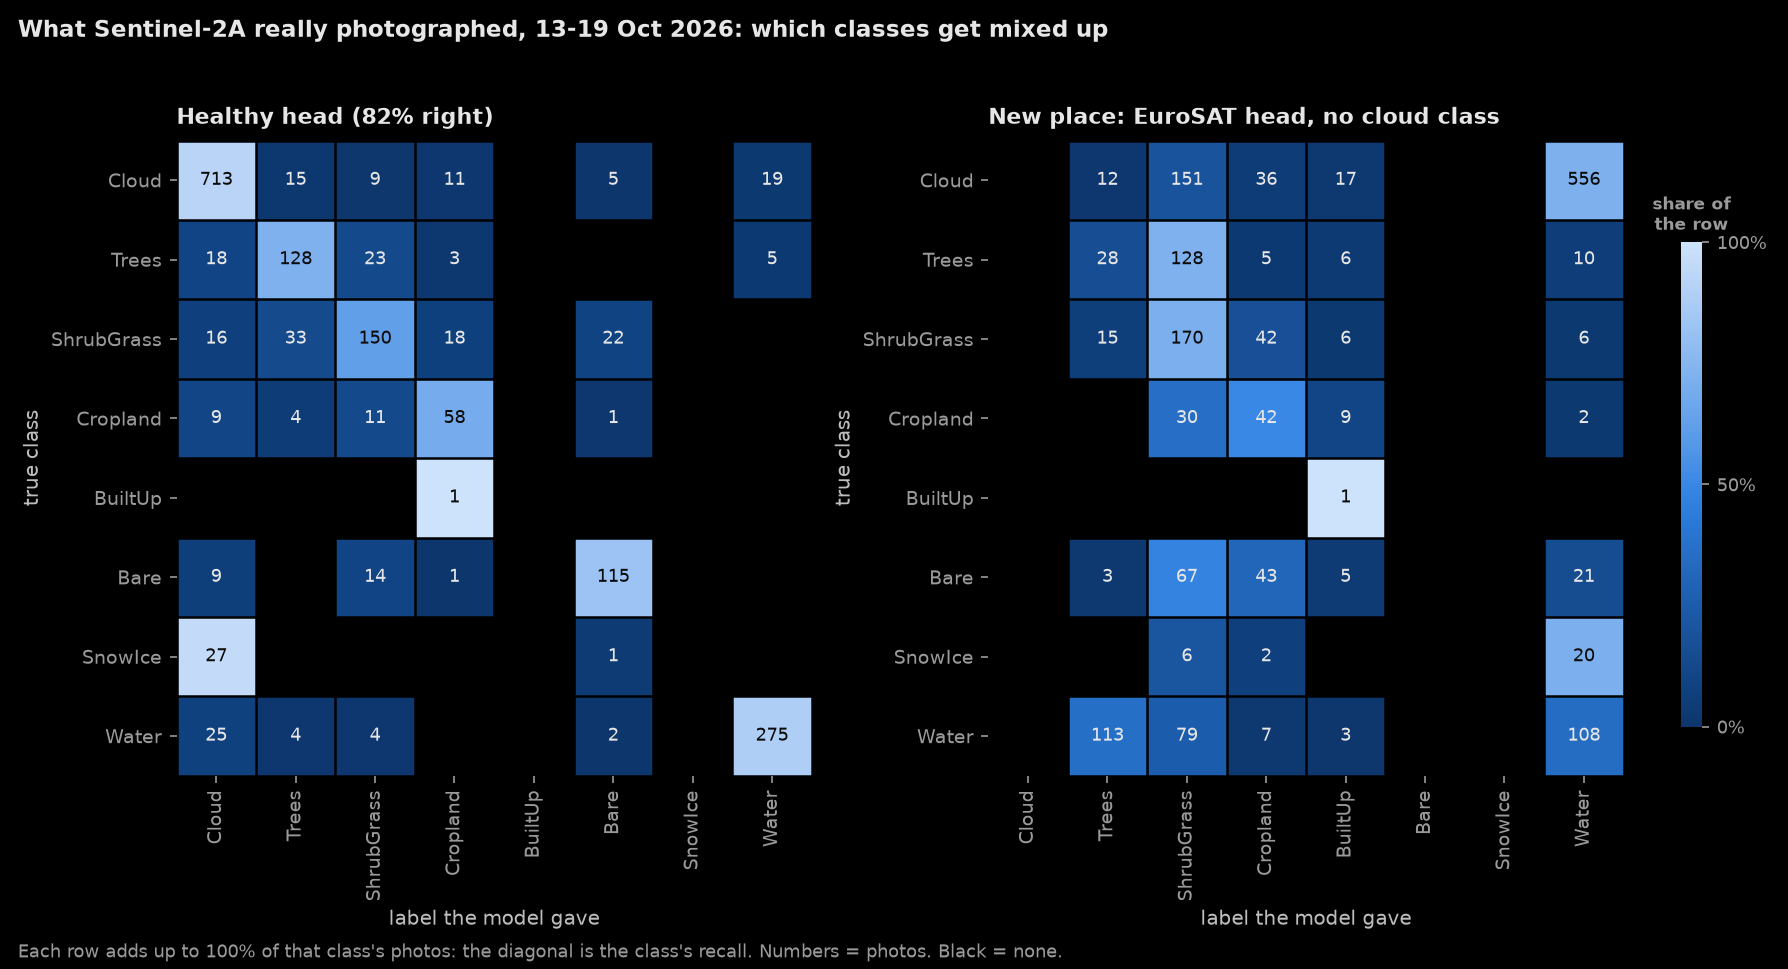

In [21]:
figure("confusion_real.png")

**What we learned.** On the balanced test sets (AID, EuroSAT) every metric agrees with accuracy. On the real
photos they don't: the healthy head is 82% right, but it **never** says SnowIce (all 28 become Cloud) or
BuiltUp. Over classes with at least 5 test photos its balanced accuracy is 67%. The data analysis
(01_data) explains why: snow and cloud are both blown-out white in colour photos.

*Results: `results/11_metrics/`. Rerun: `python -m src.eval.metrics_report`.*

## Experiment 12 · Thu 22 Oct · Retraining with what the data showed

**Question.** The data analysis (01_data) found three fixable problems on the real photos. Does fixing them make
the onboard model better, and does a better model make the ground's numbers better?

| What the data showed | Fix tried |
|---|---|
| Rare classes drowned by cloud (46%); snow never predicted | **balance the classes** in training, then **correct the chances** back to the real class mix |
| Snow and cloud both blown-out white in colour | add six **infrared** numbers (snow index NDSI, SWIR, vegetation index NDVI) from `src/data/s2_bands.py` |
| Only 15 snow and 3 built-up training photos | **3 more weeks** of what Sentinel-2A photographed (15 Sep - 5 Oct), training only |
| Is the 90M image model the limit? | the **bigger SigLIP (400M)**, embeddings made on a Kaggle GPU |

**Rules:** the test is always the same (13-19 Oct). Settings are picked on the tuning day or by cross-validation on
the training photos, never on the test. Recipes change one thing at a time. Which recipe goes into the audit was
fixed before seeing any result (recipe 5).

In [22]:
runs = pd.read_csv(find("retrain_real_*.csv")[-1])
show = runs[["recipe", "training_photos", "accuracy", "balanced_accuracy", "balanced_accuracy_low", "balanced_accuracy_high",
             "macro_f1", "recall_SnowIce", "recall_Cropland", "calibration_error", "brier"]].copy()
for col in ["accuracy", "balanced_accuracy", "balanced_accuracy_low", "balanced_accuracy_high", "macro_f1", "recall_SnowIce", "recall_Cropland"]:
    show[col] = (100 * show[col]).round(1)
show.rename(columns={"balanced_accuracy_low": "balanced low", "balanced_accuracy_high": "balanced high"})

,recipe,training_photos,accuracy,balanced_accuracy,balanced low,balanced high,macro_f1,recall_SnowIce,recall_Cropland,calibration_error,brier
0,1 baseline (as in experiments 9-11),1525,82.3,67,64.7,69,66.4,0,69.9,0.0293,0.2661
1,2 + balanced classes,1525,63.9,69.1,65.5,72.7,62.4,50,72.3,0.1649,0.4257
2,3 + chances corrected to the real mix,1525,81.1,64.8,62.4,67,64.9,0,62.6,0.0504,0.2818
3,4 + infrared bands,1525,82.2,67,64.5,69.8,68.1,7.1,62.6,0.0524,0.2605
4,5 + 3 more weeks of training photos,7158,84.7,73.1,70,76.4,75.9,32.1,65.1,0.0118,0.2164
5,6 + bigger image model (SigLIP 400M),7158,85.6,74.7,71.6,77.9,77.5,32.1,69.9,0.0122,0.2067
6,check: baseline + infrared only,1525,83.2,69.2,66.8,71.8,69.4,7.1,69.9,0.0143,0.2408
7,check: baseline + more days only,7158,83.6,70.5,67.4,74,72.6,21.4,67.5,0.0261,0.2333


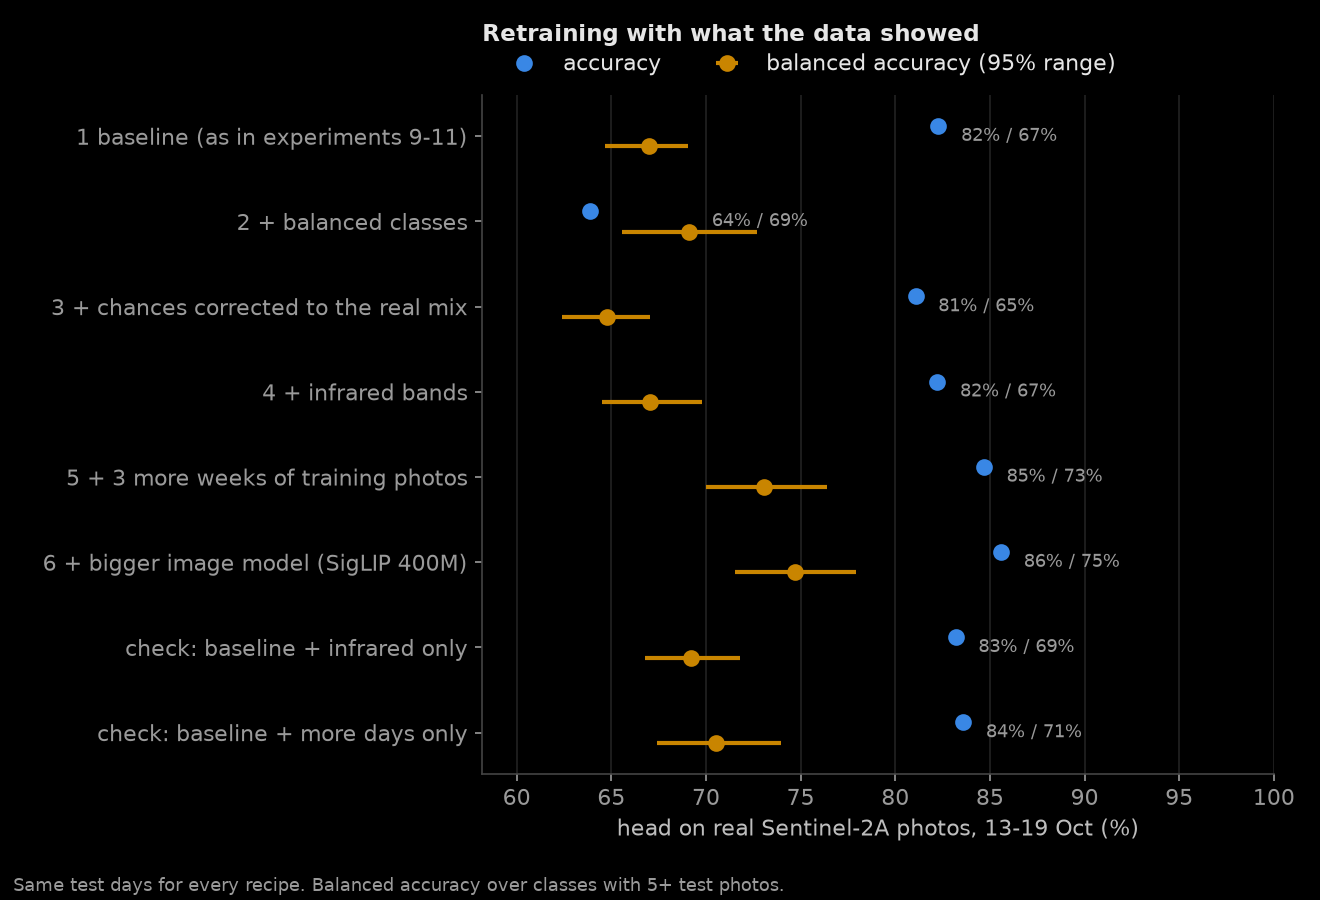

In [23]:
figure("retrain.png")

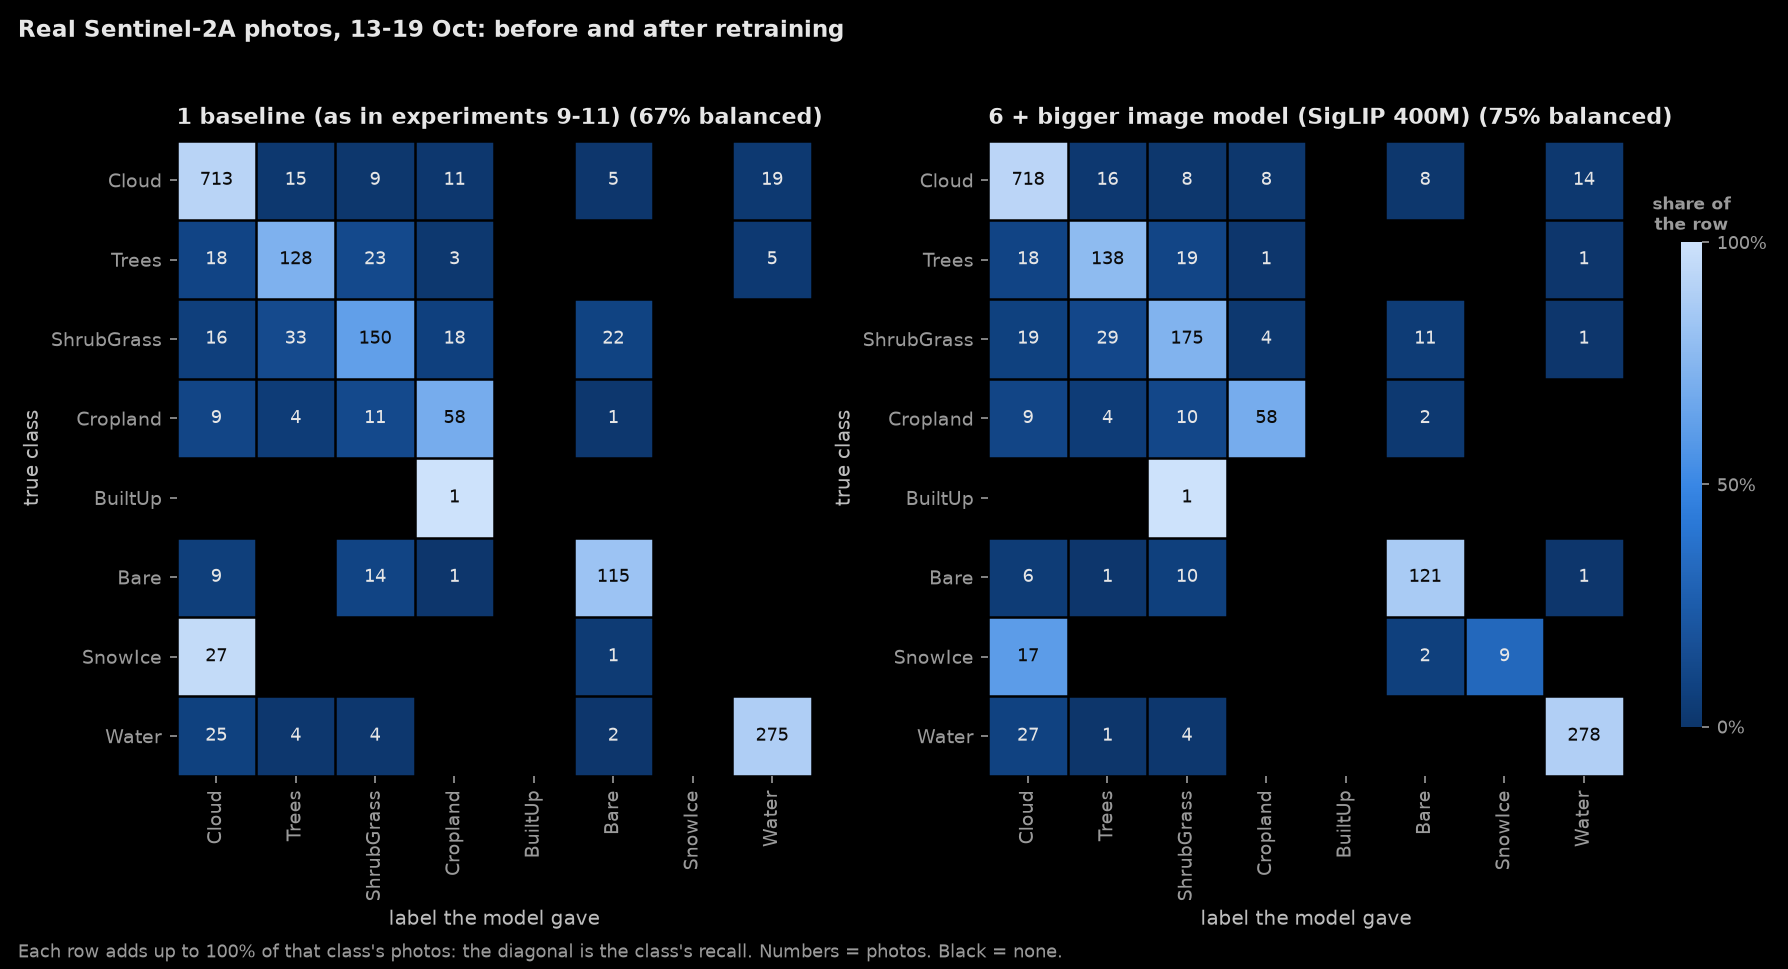

In [24]:
figure("confusion_retrained.png")

In [25]:
audit12 = pd.read_csv(find("retrain_audit_*.csv")[-1])
keep = audit12[audit12.method.isin(["labels only", "triage (v4)", "audit, self-check"]) & audit12.rate_mbps.isin([0.05, 0.25])]
cell = keep.groupby(["scenario", "rate_mbps", "method", "head"]).agg(error=("rmse_pts", "mean"), held=("holds_scaled+1", "mean"))
cell = cell["error"].round(2).astype(str) + " / " + (100 * cell["held"]).round().astype(int).astype(str) + "%"
cell.unstack("head").rename_axis(columns="error (points) / 90% bar held")

error (points) / 90% bar held                        baseline head  \
scenario                 rate_mbps method                            
bit flips                0.05      audit, self-check     5.5 / 97%   
                                   labels only         10.63 / 27%   
                                   triage (v4)         10.78 / 27%   
                         0.25      audit, self-check    1.73 / 96%   
                                   labels only         10.63 / 27%   
                                   triage (v4)          6.66 / 55%   
damaged camera: blur     0.05      audit, self-check    3.56 / 97%   
                                   labels only          4.52 / 51%   
                                   triage (v4)          3.28 / 67%   
                         0.25      audit, self-check    1.15 / 97%   
                                   labels only          4.52 / 51%   
                                   triage (v4)          1.24 / 92%   
damaged camera: noise    0.05      audit, self-check    3.96 / 97%   
                                   labels only          3.96 / 51%   
                                   triage (v4)          2.67 / 71%   
                         0.25      audit, self-check    1.29 / 94%   
                                   labels only          3.96 / 51%   
                                   triage (v4)          1.12 / 93%   
healthy head             0.05      audit, self-check    3.56 / 98%   
                                   labels only          1.89 / 80%   
                                   triage (v4)          1.54 / 84%   
                         0.25      audit, self-check     1.1 / 97%   
                                   labels only          1.89 / 80%   
                                   triage (v4)          0.67 / 96%   
new place (EuroSAT head) 0.05      audit, self-check    5.34 / 98%   
                                   labels only          19.54 / 9%   
                                   triage (v4)         16.63 / 20%   
                         0.25      audit, self-check    1.85 / 95%   
                                   labels only          19.54 / 9%   
                                   triage (v4)          9.08 / 58%   
silent swap              0.05      audit, self-check    3.64 / 98%   
                                   labels only          1.69 / 82%   
                                   triage (v4)          1.51 / 84%   
                         0.25      audit, self-check    1.11 / 97%   
                                   labels only          1.69 / 82%   
                                   triage (v4)          0.75 / 95%   

error (points) / 90% bar held                        retrained head (5 + 3 more weeks of training photos)  
scenario                 rate_mbps method                                                                  
bit flips                0.05      audit, self-check                                           5.04 / 96%  
                                   labels only                                                 7.78 / 45%  
                                   triage (v4)                                                 4.22 / 67%  
                         0.25      audit, self-check                                           1.73 / 95%  
                                   labels only                                                 7.78 / 45%  
                                   triage (v4)                                                 1.57 / 92%  
damaged camera: blur     0.05      audit, self-check                                           3.58 / 98%  
                                   labels only                                                 4.82 / 53%  
                                   triage (v4)                                                 3.34 / 70%  
                         0.25      audit, self-check                                           1.06 / 96%  
                                   labels o

**What we learned.**
- **More real data is the biggest win.** Three more weeks of training photos (1,525 -> 7,158; snow 15 -> 120)
  lifts balanced accuracy from 67.0% to 70.5% on its own, and snow found from 0% to 21%.
- **Balancing the classes alone is a trap.** It finds half the snow photos, but only by guessing snow (and other
  rare classes) far more often: accuracy falls to 64% and the chances stop being honest (calibration error 0.17).
  Correcting the chances back to the real class mix undoes the damage, and the snow gain with it. Balancing
  can't teach the model to *see* snow when the colour pixels don't show it.
- **Infrared helps a little, not a lot.** It adds about 2 points of balanced accuracy and finds some snow, but
  thick ice clouds also look snow-like in short-wave infrared (01_data, 3.2). Adding the latitude (we tried) did
  not help either.
- **All data fixes together (recipe 5):** 84.7% accurate (from 82.3%), **73.1% balanced** (from 67.0%),
  macro-F1 75.9% (from 66.4%), snow found 32% (from 0%), and *more* honest chances (calibration error 0.012
  from 0.029).
- **The bigger image model (SigLIP 400M, Kaggle GPU) adds only a little more:** 85.6% accurate, 74.7% balanced
  (ranges overlap with recipe 5), for 4.5x the weights and roughly 15-20x the compute. As on EuroSAT (experiment 5):
  better data beats a bigger model; the 90M model stays the onboard choice.
- **A better onboard model makes the ground's numbers more precise, but not honest by itself.** With the retrained
  head, the audit's error at 0.25 Mbps drops from 1.10 to 0.83 points (bars still hold 96%), and triage's from 0.67
  to 0.45. But labels alone still mislead (bar held 87%), and with a broken model (new place) labels and triage
  still fail (bars 9% and 20%). Retraining improves the model; the audit is what keeps the numbers honest.

*Results: `results/12_retraining/`. Rerun: `python -m src.model.retrain` and `python -m src.model.retrain --audit`
(the big model needs `python -m src.cloud.kaggle_upload` and `python -m src.cloud.kaggle_run --command "src.model.retrain --embed siglip" --dataset s2real` first).*

## Where this leaves the project

1. **Data first (01_data):** two of three data sets are clean; the real replay is uneven and 14% messy, and snow
   looks like cloud in colour. The results hold with and without the messy photos.
2. **Onboard labelling (experiments 1-7, 11-12):** a frozen SigLIP with a 30 KB head beats Gemma 3 (the model NASA
   flew) by far; more real training days make it better still (73% balanced on real photos).
3. **The main result (experiments 8-10):** labels alone can't be trusted, and nobody can tell when they go wrong.
   Random checks with known chances keep the ground's numbers honest whatever the onboard model is like, and a
   self-check notices when the model breaks.
4. **Next:** a person re-checks the flagged labels, time and energy on a Jetson Orin, a demo video, and the
   IGARSS 2027 paper (`paper/outline.md`).